In [3]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")



PROGRAMACION PYTHON AVANZADO - UPSO <br>
PROYECTO 2: Regresion lineal multiple <br>
INTEGRANTES: Carluccio Ros Bruno & Gonzalez Agustin <br>
DATASET: sample_10k_rows.csv <br>
OBSERVACIONES: El dataset seleccionado es una lista de personas de las cuales conocemos datos (edad, ingreso ahorro, habitos, etc) utilizando regresion lineal multiple buscamos mediante esos datos, estimar o predecir el patrimonio neto de la persona (net_worth)

1. Carga de Datos y visualización de variables.

filas y columnas:
 (10000, 274)
Exploracion:
   synthetic_person_id dataset_version  generation_seed        country  \
0        SYN_00000001           1.0.0         20260914    Switzerland   
1        SYN_00000002           1.0.0         20260914  United States   
2        SYN_00000003           1.0.0         20260914     Bangladesh   
3        SYN_00000004           1.0.0         20260914        Ireland   
4        SYN_00000005           1.0.0         20260914          India   

      region urban_rural  age age_group      gender marital_status  ...  \
0     Zurich       Rural   40     36-45        Male        Married  ...   
1  Northeast       Urban   62     56-65        Male         Single  ...   
2   Rajshahi       Urban   37     36-45      Female       Divorced  ...   
3     Ulster       Urban   68       65+        Male         Single  ...   
4      Delhi    Suburban   52     46-55  Non-binary       Divorced  ...   

   asset_diversification_score income_diversification_score  \
0

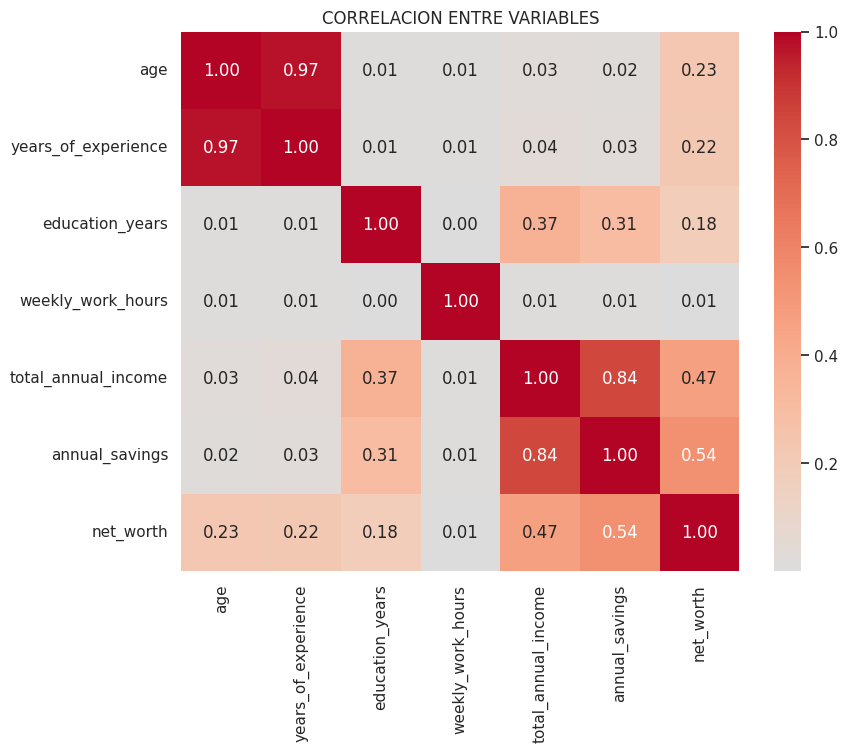

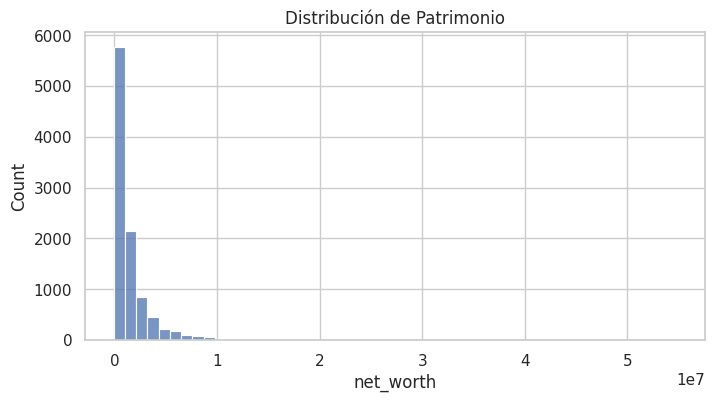

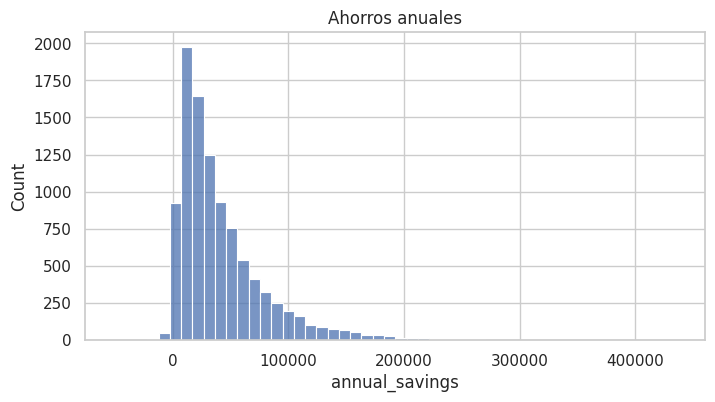

In [4]:
#importamos dataframe como df
df = pd.read_csv("sample_10k_rows.csv")
print("filas y columnas:\n", df.shape)
print("Exploracion:\n", df.head()) #exploracion
df.describe()
df.info()
print("Valores faltantes por columna:\n", df.isna().sum())

# variable que quiero predecir (target) y variables con las que la predigo (entrada)
colTarget = "net_worth" #PATRIMONIO NETO
colEntrada = ["age", "years_of_experience", "education_years",
              "weekly_work_hours", "total_annual_income", "annual_savings"]

# seleccionamos solo con esas columnas y saco filas con nulos
#(NO HAY NULOS EN NUESTRO CASO PERO ES BUENA PRACTICA)
datos = df[colEntrada + [colTarget]].dropna()
print("Visualizacion de datos sin null", datos.head())
print("Descripcion sin null", datos.describe())

#VISUALIZACION

# grafico de correlación entre variables
plt.figure(figsize=(9, 7))
sns.heatmap(datos.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("CORRELACION ENTRE VARIABLES"); plt.show()

# histograma del target
plt.figure(figsize=(8, 4))
sns.histplot(datos["net_worth"], bins=50)
plt.title("Distribución de Patrimonio")
plt.show()

# histograma de una variable de entrada
plt.figure(figsize=(8, 4))
sns.histplot(datos["annual_savings"], bins=50)
plt.title("Ahorros anuales")
plt.show()


2. Cambio de estructura de datos a matricial

In [5]:
# matriz con una fila por persona y una columna por variable de entrada
matrizX = datos[colEntrada].to_numpy()
# vector con el patrimonio de cada persona
vectorY = datos[colTarget].to_numpy()
print("X:", matrizX.shape)
print("Y:", vectorY.shape)


X: (10000, 6)
Y: (10000,)


3. Particionado de datos en Entrenamiento y Test

In [6]:
# 80 % entrenamiento, 20 % testeo
xTrain, xTest, yTrain, yTest = train_test_split(matrizX, vectorY, test_size=0.2, random_state=42)
print("train:", xTrain.shape[0], "filas / test:", xTest.shape[0], "filasss")



train: 8000 filas / test: 2000 filasss


4. Generación del modelo con los datos de Entrenamiento

In [7]:
# fit busca los coeficientes que minimizan el error cuadrático en train
modelo = LinearRegression()
modelo.fit(xTrain, yTrain)

print("intercepto:", round(modelo.intercept_, 2))
tablaCoef = pd.DataFrame({
    "variable": colEntrada,
    "coeficiente": modelo.coef_,
    "coefEstandarizado": modelo.coef_ * xTrain.std(axis=0),
})
print(tablaCoef.sort_values("coefEstandarizado", key=abs, ascending=False).round(2))


intercepto: -2323890.05
              variable  coeficiente  coefEstandarizado
5       annual_savings        32.33         1322240.08
0                  age     52412.70          725211.24
4  total_annual_income         1.47          167790.40
1  years_of_experience    -12377.73         -152779.85
3    weekly_work_hours     -1380.05          -12154.57
2      education_years       834.05            2383.86


5. Evaluación del modelo con los datos de Entrenamiento

In [8]:
predTrain = modelo.predict(xTrain)
maeTrain = mean_absolute_error(yTrain, predTrain)
rmseTrain = mean_squared_error(yTrain, predTrain) ** 0.5
r2Train = r2_score(yTrain, predTrain)
print(f"MAE train:  {maeTrain:,.0f}")
print(f"RMSE train: {rmseTrain:,.0f}")
print(f"R2 train:   {r2Train:.3f}")


MAE train:  1,056,793
RMSE train: 2,164,709
R2 train:   0.351


6. Evaluación del modelo con los datos de Test

In [9]:
#aca guardamos las metricas train y test
resultados = []

def evaluar(nombre, modelo, cols, xTr, xTe, yTr, yTe):

    idx = [colEntrada.index(c) for c in cols]
    # fit: el modelo aprende con las filas de entrenamiento, usando solo las columnas elegidas
    modelo.fit(xTr[:, idx], yTr)
    # predict: predice para train y para test (con las mismas columnas que usó para aprender)
    predTr, predTe = modelo.predict(xTr[:, idx]), modelo.predict(xTe[:, idx])
    # armo un diccionario con las métricas de este modelo (una fila de la tabla)
    fila = {
        "modelo": nombre,
        "MAE test": mean_absolute_error(yTe, predTe),
        "RMSE test": mean_squared_error(yTe, predTe) ** 0.5,
        "R² train": r2_score(yTr, predTr),
        "R² test": r2_score(yTe, predTe),
    }
    # guardo la fila en la lista de resultados
    resultados.append(fila)
    # devuelvo el modelo ya entrenado y sus predicciones sobre test
    return modelo, predTe

def tabla():
    # convierte la lista de filas en una tabla pandas
    return pd.DataFrame(resultados).set_index("modelo").round(3)



In [10]:

# Baseline
evaluar("Baseline (promedio)\n", DummyRegressor(strategy="mean"), colEntrada,
        xTrain, xTest, yTrain, yTest)

# Simple
evaluar("Simple: annual_savings\n", LinearRegression(), ["annual_savings"],
        xTrain, xTest, yTrain, yTest)


#  Múltiple completa: 6 variables
modelo, predTest = evaluar("Multiple:\n", LinearRegression(), colEntrada,
            xTrain, xTest, yTrain, yTest)

print(tabla())

                             MAE test    RMSE test  R² train  R² test
modelo                                                               
Baseline (promedio)\n     1405860.368  2548091.656     0.000   -0.001
Simple: annual_savings\n  1058561.047  2221147.269     0.303    0.240
Multiple:\n               1059490.353  2132690.989     0.351    0.299


7. Visualizacion de graficos: reales vs predichos

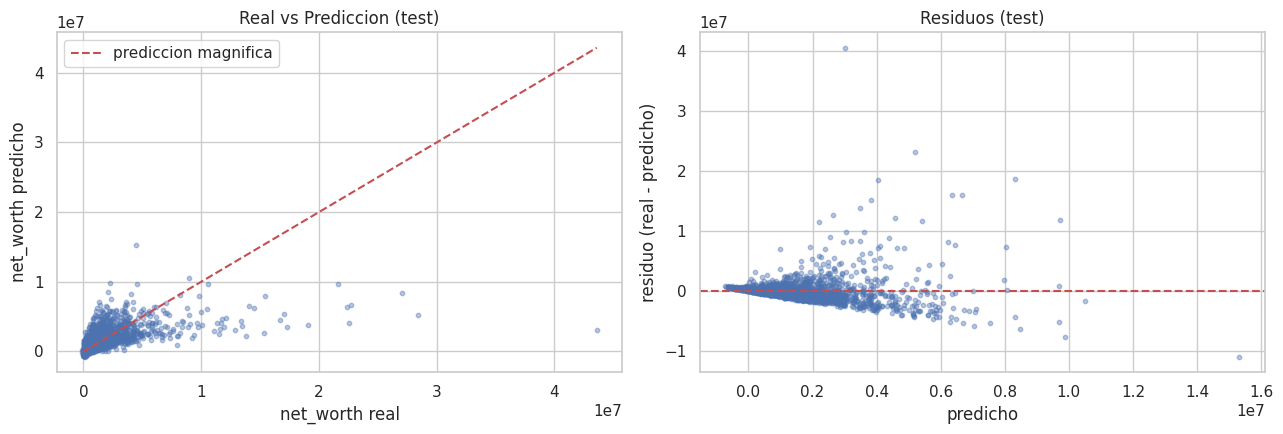

In [11]:
# residuo = lo que tiene la persona de verdad menos lo que predijo el modelo
residuos = yTest - predTest
# figura de 1 fla y 2 graficos
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
#grafico izquierda
ejes[0].scatter(yTest, predTest, alpha=0.4, s=10)
limites = [yTest.min(), yTest.max()]
#dibujo de linea roja
ejes[0].plot(limites, limites, "r--", label="prediccion magnifica")
#titulos
ejes[0].set(xlabel="net_worth real", ylabel="net_worth predicho", title="Real vs Prediccion (test)")
ejes[0].legend()

#grafico de la derecha, misma logica.
ejes[1].scatter(predTest, residuos, alpha=0.4, s=10)
ejes[1].axhline(0, color="r", ls="--")
ejes[1].set(xlabel="predicho", ylabel="residuo (real - predicho)", title="Residuos (test)")

#acommodar graficos
plt.tight_layout()
#mostrar
plt.show()


Link de Github: https://github.com/agustingonzalezgutierrez98/Proyecto-2-Regresion-Lineal.git